In [1]:
# === Imports ===
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
from astropy.coordinates import SkyCoord  # Astronomical coordinate handling
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import sys
from matplotlib.backends.backend_pdf import PdfPages  # Save multiple figures into a PDF

In [2]:
# === Defined Parameters ===
field_name = 'MISHAPS_F1_DITH0'  # Field identifier
chip_id = 'N10'  # Chip identifier
magnitude_band = 'r'  # Band used for magnitude measurement
color_band_1 = 'r'  # First band for color (e.g. r-z)
color_band_2 = 'z'  # Second band for color
field_chip_label = f"{field_name}_{chip_id}"  # Combined label for file references

In [3]:
# CMD (Color-Magnitude Diagram) Parameters
default_color_cut = 1.06
magnitude_cut = 17.3
color_range_min = 0.0
color_range_max = 2.0
msto_shift_value = 3.5  # Main Sequence Turn-Off shift

In [4]:
# Adjust defaults for specific color combinations
if color_band_2 == "z" and color_band_1 == "r":
    default_color_cut = 0.46
    color_range_max = 1.0
    msto_shift_value = 3.0

In [5]:
# Enable interactive plots if enough command-line arguments are provided
interactive_mode = False
if len(sys.argv) >= 6:
    interactive_mode = True

# Optionally override color and magnitude cuts
if len(sys.argv) >= 7:
    default_color_cut = float(sys.argv[6])
    print("Color cut set to:", default_color_cut)

if len(sys.argv) >= 8:
    magnitude_cut = float(sys.argv[7])
    print("Magnitude cut set to:", magnitude_cut)

print("Using magnitude and color bands:", magnitude_band, color_band_1, color_band_2)

Using magnitude and color bands: r r z


In [15]:
# Optional positional filtering via RA/Dec limits
apply_position_cut = False
ra_min, ra_max = -1, -1
dec_min, dec_max = -1, -1


# If you've given it an explicit position cut, use those values. Else use the min and max RA and Dec from the data
if apply_position_cut==True:
    photometric_catalog = photometric_catalog[(photometric_catalog[:, ra_col_index] >= ra_min) & (photometric_catalog[:, ra_col_index] < ra_max) & (photometric_catalog[:,dec_col_index] >= dec_min) & (photometric_catalog[:,dec_col_index] < dec_max)]
else:
    ra_min = np.nanmin(photometric_catalog[:, ra_col_index])
    ra_max = np.nanmax(photometric_catalog[:, ra_col_index]) 
    dec_min = np.nanmin(photometric_catalog[:, dec_col_index])
    dec_max = np.nanmax(photometric_catalog[:, dec_col_index])

In [7]:
# === Load Configuration from Options File ===
options = pyp2options.pip2options('/home/bernthold.17/SURP2025/fit_models/')

/home/bernthold.17/SURP2025/fit_models/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)


In [8]:
# Column indices for quality flags
qflag_mag = options['cmdq-' + magnitude_band] - 1
qflag_c1 = options['cmdq-' + color_band_1] - 1
qflag_c2 = options['cmdq-' + color_band_2] - 1

# Column indices for magnitudes
mag_col_index = options['cmdm-' + magnitude_band] - 1
c1_col_index = options['cmdm-' + color_band_1] - 1
c2_col_index = options['cmdm-' + color_band_2] - 1

# Column indices for position
ra_col_index = 1
dec_col_index = 2

In [9]:
# Reference directory for outputs
reference_directory = '/home/bernthold.17/SURP2025/fit_models/'

In [10]:
# Image grid dimensions
grid_cols = 4
grid_rows = 8
subimage_size = 2048.0 / grid_cols

In [11]:
# === Red Clump Color Reference Function ===
# The numbers come from the Nataf papers --> Look them up
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0, 0)
def red_clump_color(l, b):
    """Returns the expected intrinsic color of the red clump stars given Galactic coordinates."""
    I_0 = 14.3955 - 0.0239 * l + 0.0122 * np.abs(b) # Dereddened I mag of the red clump (rc)
    I_mag = np.array([I_0, I_0 + 0.737, I_0 - 1.07]) # The I mag of the rc, red giant branch (rgbb),
                                                        # and asymptotic giant branch (agbb)
    dis_mod = I_mag - 14.3955 + 5.0 * np.log10(8178.0) - 5.0 # Distance modulus of bar peak density
    distance = 10**(0.2 * (dis_mod + 5.0)) # Distance from ... --> Figure it out
    V_mag = 1.060 + I_mag
    
    # Use the relations between U, B, V, R, I mags and Sloan Digital Sky Survey (SDSS) u, g, r, i, z mags to get 
     # the g, r, i, z mags
    g_sdss = V_mag + 0.553 # g sdss filter (mag)
    r_sdss = V_mag - 0.327 # r sdss  filter (mag)
    i_sdss = V_mag - 0.600 # i sdss filter (mag)
    
    gmi_sdss = g_sdss - i_sdss # (g-i) sdss color
    
    rgbb_r_sdss = 1.060 + I_mag + 0.737 - 0.327 # r sdss filter of the red giant branch
    agbb_r_sdss = 1.060 + I_mag - 1.070 - 0.327 # r sdss filter of the asymptotic giant branch
    rgbb_gmi_sdss = 0.553 + 0.600 - 0.060 # (g-i) sdss color of the red giant branch
    agbb_gmi_sdss = 0.553 + 0.600 + 0.200 # (g-i) sdss color of the asymptotic giant branch
    
    print("r sdss:", r_sdss, rgbb_r_sdss, agbb_r_sdss)
    print("gmi sdss:", gmi_sdss, rgbb_gmi_sdss, agbb_gmi_sdss)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0, 10):
        gpmgs = -0.01808 - 0.13595 * gmi_sdss + 0.01941 * gmi_sdss**2 - 0.00183 * gmi_sdss**3
        rpmrs = -0.01836 - 0.03577 * gmi_sdss + 0.02612 * gmi_sdss**2 - 0.00558 * gmi_sdss**3
        ipmis = 0.01170 - 0.00400 * gmi_sdss + 0.00066 * gmi_sdss**2 - 0.00058 * gmi_sdss**3
        g_ps1 = g_sdss + gpmgs #g panstarrs
        r_ps1 = r_sdss + rpmrs #r panstarrs
        i_ps1 = i_sdss + ipmis #i panstarrs
        gmi_ps1 = g_ps1 - i_ps1 #gmi panstarrs
        rmi_ps1 = r_ps1 - i_ps1 #rmi panstarrs
        imz_ps1 = 0.234625 + 0.211715 * (gmi_ps1 - 1.25) #i-z panstarrs
        rmz_ps1 = rmi_ps1 + imz_ps1 #r-z panstarrs
        z_ps1 = r_ps1 - rmz_ps1 #z panstarrs

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":g_ps1[0], "clump-r":r_ps1[0], "clump-i":i_ps1[0], "clump-z":z_ps1[0],
           "rgbb-g":g_ps1[1], "rgbb-r":r_ps1[1], "rgbb-i":i_ps1[1], "rgbb-z":z_ps1[1],
           "agbb-g":g_ps1[2], "agbb-r":r_ps1[2], "agbb-i":i_ps1[2], "agbb-z":z_ps1[2],
           "distance":distance[0], "distance_modulus":dis_mod[0]}

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

In [12]:
# === Load and Filter Photometric Catalog ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"
print(f"Reading catalog from: {catalog_path}")

Reading catalog from: /home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_DITH0_N10.cmd.calibrate_ps


In [13]:
# Load the photometric catalog with mixed data types
try:
    photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace=True, comment='#', header=None)
    photometric_catalog = photometric_catalog_df.values  # convert to NumPy array for compatibility
except Exception as error:
    print(f"Error loading catalog: {error}")
    sys.exit(1)
#print(photometric_catalog_df.values.dtype)
#print(photometric_catalog)

/tmp/slurmtmp.8811301/ipykernel_599498/2368393508.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace=True, comment='#', header=None)


In [14]:
# Apply magnitude quality flag filters
valid_quality = (
    #(photometric_catalog[:, qflag_mag] == 1) &
    (photometric_catalog[:, qflag_c1] == 1) &
    (photometric_catalog[:, qflag_c2] == 1)
)
filtered_catalog = photometric_catalog[valid_quality]
print(f"Stars passing quality cuts: {len(filtered_catalog)}")

Stars passing quality cuts: 34630


In [16]:
# Optional position-based filtering using RA/Dec limits
if apply_position_cut:
    ra_values = filtered_catalog[:, ra_col_index]
    dec_values = filtered_catalog[:, dec_col_index]
    within_bounds = (
        (ra_values > ra_min) & (ra_values < ra_max) &
        (dec_values > dec_min) & (dec_values < dec_max)
    )
    filtered_catalog = filtered_catalog[within_bounds]

print(f"Stars within RA/Dec bounds: {len(filtered_catalog)}")

Stars within RA/Dec bounds: 34630


In [17]:
# Get the mean RA and Dec
ra = np.nanmean(filtered_catalog[:, ra_col_index])
dec = np.nanmean(filtered_catalog[:, dec_col_index])

# Get the l and b coordinates
coords = SkyCoord(ra,dec,frame = 'icrs',unit = u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
print("Galactic Coordinates:",l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump = red_clump_color(l, b)

clumpmag0 = red_clump["clump-" + magnitude_band]
rgbbmag0 = red_clump["rgbb-" + magnitude_band]
agbbmag0 = red_clump["agbb-" + magnitude_band]

print('Red Clump Initial Magnitude:', clumpmag0)
print('Red Giant Branch Initial Magnitude:',rgbbmag0)
print('Asymptotic Giant Branch Initial Magnitude:',agbbmag0)

Galactic Coordinates: 4.835380350738254 -7.903082849743301
r sdss: [15.10935202 15.84635202 14.03935202] [15.84635202 16.58335202 14.77635202] [14.03935202 14.77635202 12.96935202]
gmi sdss: [1.153 1.153 1.153] 1.093 1.353
Red Clump Initial Magnitude: 15.075920301604565
Red Giant Branch Initial Magnitude: 15.812920301604565
Asymptotic Giant Branch Initial Magnitude: 14.005920301604565


In [18]:
# === Red Clump Model (Quadratic + Gaussian) ===
def rcmodel(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0))**2/sigma_rc**2)
    return A + B + C + D     

In [19]:
# === Red Clump Gaussian ===
def cgauss(x, amplitude, mean, sigma):
    x = np.float64(x)
    return amplitude/(np.sqrt(2*np.pi*sigma**2))*np.exp(-0.5*(x-mean)**2/sigma**2)

In [20]:
# === Construct Color-Magnitude Diagram (CMD) ===
# Compute color index and magnitude
color_index = filtered_catalog[:, c1_col_index] - filtered_catalog[:, c2_col_index]
magnitude_values = filtered_catalog[:, mag_col_index]

In [21]:
# === Giant Star Selection ===
# Filter stars that are likely giants
# Filter for the giants
giant_candidates = filtered_catalog[(color_index > default_color_cut) & (magnitude_values < magnitude_cut)]

giant_colors = giant_candidates[:, c1_col_index] - giant_candidates[:, c2_col_index]
giant_magnitudes = giant_candidates[:, mag_col_index]

print(f"Selected {len(giant_candidates)} giant star candidates")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
hist_counts_giant, bin_edges_giant = np.histogram(giant_magnitudes, range = (magnitude_cut - 4.0,magnitude_cut), 
                                                  bins = 40, density = False) # bins the magnitudes of the giants
bin_centers_giant = 0.5 * (bin_edges_giant[0:-1] + bin_edges_giant[1:]) # calculates bin centers from the bin edges

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0 = (hist_counts_giant>0)
hist_counts_m0 = hist_counts_giant[mask_0]
bin_centers_m0 = bin_centers_giant[mask_0]

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit


par_0,cov_0 = spopt.curve_fit(rcmodel, bin_centers_m0, hist_counts_m0, p0 = initial_guess_0, 
                              sigma = np.sqrt(hist_counts_m0))
print(f"rcmodel Fit Results:\nAmplitude = {par_0[0]:.2f}\n  Slope = {par_0[1]:.2f}\n Magnitude of red clump = {par_0[2]:.2f}\n  Number of red clump stars = {par_0[3]:.2f}\n  Sigma = {par_0[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0

print(f"Giant magnitude range: {np.min(giant_candidates[:, mag_col_index])} to {np.max(giant_candidates[:, mag_col_index])}")

# === Red Clump Star Selection ===
# Filter stars that are likely within the red clump
clump_candidates = giant_candidates[np.abs(giant_candidates[:, mag_col_index] - par_0[2]) < 2 * par_0[4]]

clump_colors = clump_candidates[:, c1_col_index] - clump_candidates[:, c2_col_index]
clump_magnitudes = clump_candidates[:, mag_col_index]

print(f"Selected {len(clump_candidates)} red clump candidates")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
hist_counts_clump, bin_edges_clump = np.histogram(clump_colors, range = (default_color_cut, default_color_cut + 1.5), 
                                                  bins=60)
bin_centers_clump = 0.5 * (bin_edges_clump[:-1] + bin_edges_clump[1:])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1 = (hist_counts_clump>0)
hist_counts_m1 = hist_counts_clump[mask_1]
bin_centers_m1 = bin_centers_clump[mask_1]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_1 = [par_0[3] + 0.0, default_color_cut + 0.2, 0.2]

par_1, cov_1 = spopt.curve_fit(cgauss, bin_centers_m1, hist_counts_m1, p0 = initial_guess_1, 
                               sigma=np.sqrt(hist_counts_m1))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1[0]:.2f}\n  Mean = {par_1[1]:.2f}\n Sigma = {par_1[2]:.2f}")

amplitude, mean, sigma = par_1

Selected 1529 giant star candidates
rcmodel Fit Results:
Amplitude = 14.04
  Slope = 1.36
 Magnitude of red clump = 15.93
  Number of red clump stars = 85.14
  Sigma = 0.66
Giant magnitude range: 14.06686 to 17.29979
Selected 1445 red clump candidates
cgauss Model Fit Results:
Amplitude = 29.57
  Mean = 0.74
 Sigma = 0.11


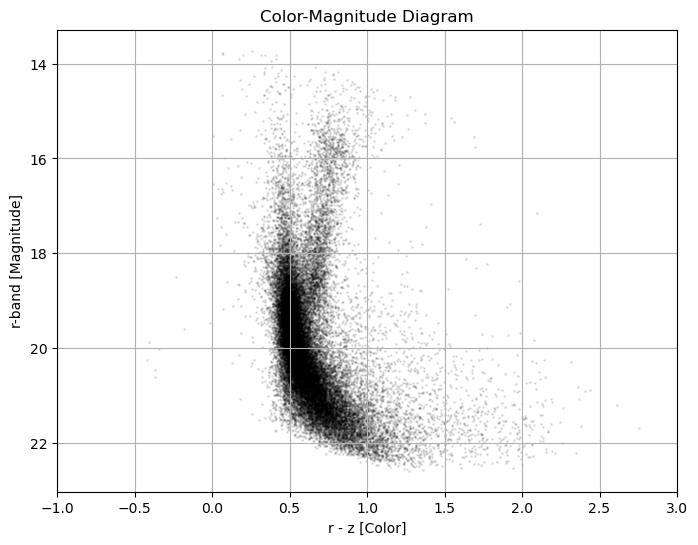

In [22]:
# Plot CMD
cmd_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values, s = 1, color = 'black', alpha = 0.1)

plt.xlim(-1,3)
plt.gca().invert_yaxis()  # Brighter stars at the top

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.title("Color-Magnitude Diagram")
plt.grid(True)

#plt.savefig("debug_cmd_all_stars.png")
#if interactive_mode:
    #plt.show()
#plt.close(cmd_fig)
plt.show()

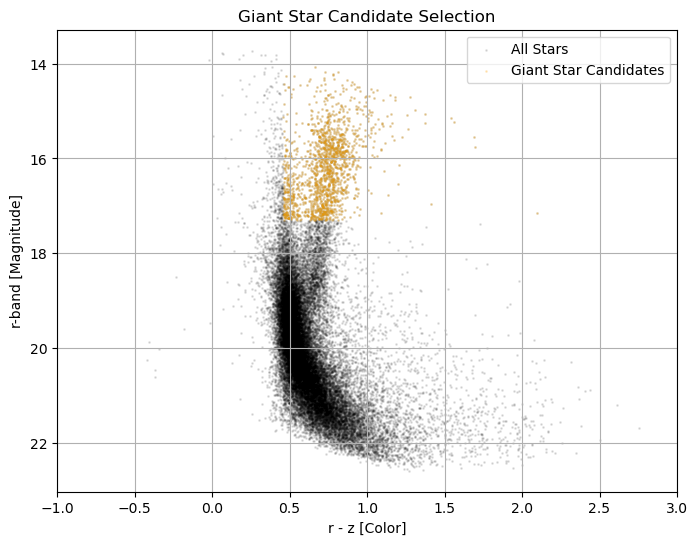

In [23]:
# Plot Giant Star Candidates on CMD
giant_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values, s = 1, color = 'black', alpha = 0.1, label = 'All Stars')
plt.scatter(giant_colors, giant_magnitudes, s = 1, color = 'orange', alpha = 0.2, label = 'Giant Star Candidates')

plt.xlim(-1,3)
plt.gca().invert_yaxis()

plt.title("Giant Star Candidate Selection")
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.grid(True)
plt.legend(loc = 'best')

#plt.savefig("debug_cmd_giant_candidates.png")
#if interactive_mode:
    #plt.show()
#plt.close(giant_fig)
plt.show()

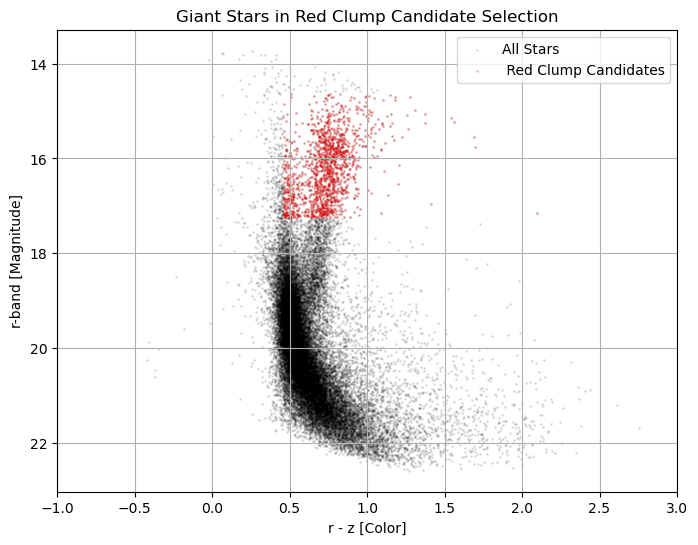

In [24]:
# Plot Red Clump Giant Star Candidates on CMD
clump_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values, s = 1, color = 'black', alpha = 0.1, label = 'All Stars')
plt.scatter(clump_colors, clump_magnitudes, s = 1, color = 'red', alpha = 0.2, label = ' Red Clump Candidates')

plt.xlim(-1,3)
plt.gca().invert_yaxis()

plt.title("Giant Stars in Red Clump Candidate Selection")
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.grid(True)
plt.legend(loc='best')

#plt.savefig("debug_cmd_clump_candidates.png")
#if interactive_mode:
    #plt.show()
#plt.close(clump_fig)
plt.show()

In [25]:
# z-mag cmd 
# distance dispersion of the clump, assume .5 kpc thickness, 8 kpc distance, how does it affect the overall spread of the magnitudes

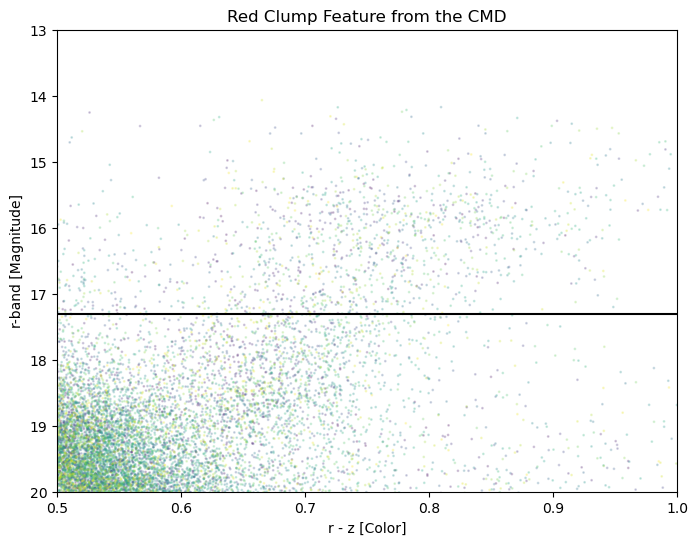

In [26]:
# Plot CMD zoomed in on red clump region and color-coded by RA
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values, c = filtered_catalog[:, ra_col_index], s = 1, alpha = 0.2, 
            rasterized = True)
plt.plot([default_color_cut, default_color_cut, color_range_max], [13.0, magnitude_cut, magnitude_cut], 'k-')

plt.xlim(0.5, color_range_max)
plt.ylim(20, 13)

plt.title('Red Clump Feature from the CMD')
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.show()

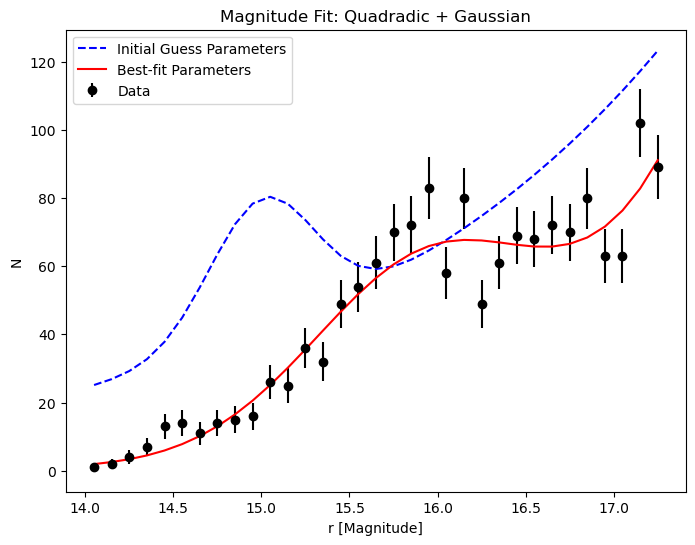

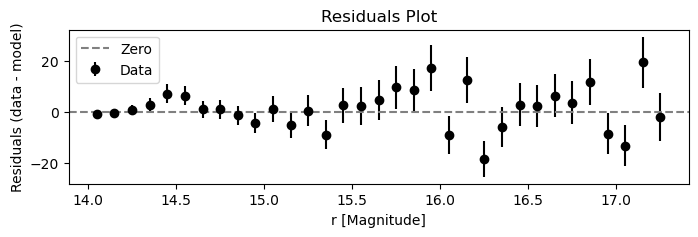

r_rc = 15.934 ± 0.113, sigma_rc =  0.659 ± 0.114, A_r = 0.858 ± 0.113


In [27]:
plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m0, hist_counts_m0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data') 

# Compute residuals
model_vals_0 = rcmodel(bin_centers_m0, *par_0)
residuals_0 = hist_counts_m0 - model_vals_0

plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *initial_guess_0), 'b--', label = 'Initial Guess Parameters')
plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *par_0), 'r-', label = 'Best-fit Parameters')

plt.xlabel(f"{magnitude_band} [Magnitude]")
plt.ylabel(f"N")
plt.title('Magnitude Fit: Quadradic + Gaussian')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize = (8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m0, residuals_0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data')
plt.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

plt.xlabel(f"{magnitude_band} [Magnitude]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(
    f"{magnitude_band}_rc = {par_0[2]:6.3f} ± {np.sqrt(cov_0[2, 2]):5.3f}, "
    f"sigma_rc = {par_0[4]:6.3f} ± {np.sqrt(cov_0[4, 4]):5.3f}, "
    f"A_{magnitude_band} = {par_0[2] - clumpmag0:5.3f} ± {np.sqrt(cov_0[2, 2]):5.3f}"
)

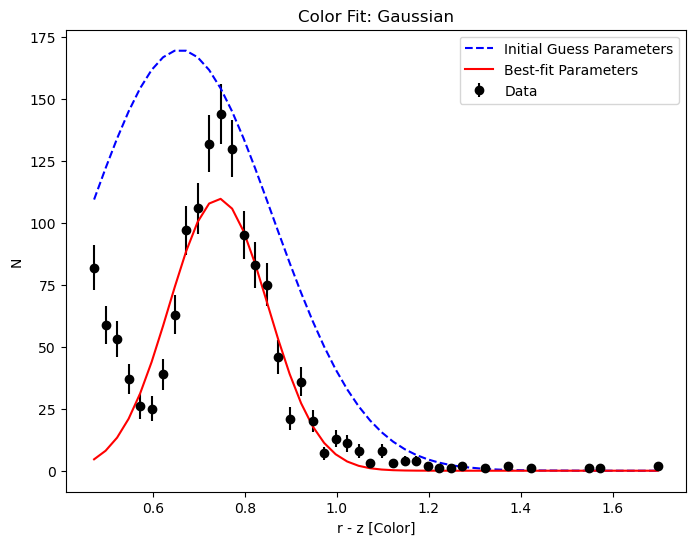

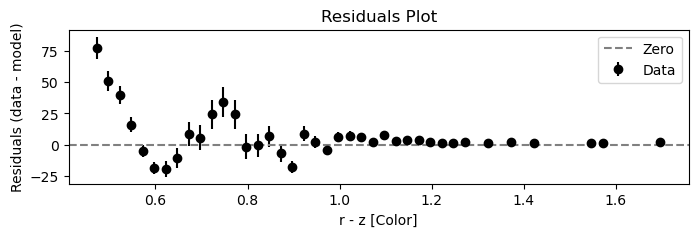

(r-z) = 0.743 ± 0.009, σ_(r-z) = 0.107 ± 0.008


In [28]:
plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m1, hist_counts_m1, yerr = np.sqrt(hist_counts_m1), fmt = 'ko', label = 'Data')

# Compute residuals
model_vals_1 = cgauss(bin_centers_m1, *par_1)
residuals_1 = hist_counts_m1 - model_vals_1

plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_1), 'b--', label = 'Initial Guess Parameters')
plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_1), 'r-', label = 'Best-fit Parameters')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"N")
plt.title('Color Fit: Gaussian')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize=(8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m1, residuals_1, yerr=np.sqrt(hist_counts_m1), fmt='ko', label = 'Data')
plt.axhline(0, color='gray', linestyle='--', label = 'Zero')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(rf"({color_band_1}-{color_band_2}) = {par_1[1]:.3f} ± {np.sqrt(cov_1[1,1]):.3f}, σ_({color_band_1}-{color_band_2}) = {par_1[2]:.3f} ± {np.sqrt(cov_1[2,2]):.3f}")

In [35]:
# Printing the results of the magnitude fit
print(
    f"{magnitude_band}_rc = {par_0[2]:6.3f} ± {np.sqrt(cov_0[2, 2]):5.3f}, "
    f"sigma_rc = {par_0[4]:6.3f} ± {np.sqrt(cov_0[4, 4]):5.3f}, "
    f"A_{magnitude_band} = {par_0[2] - clumpmag0:5.3f} ± {np.sqrt(cov_0[2, 2]):5.3f}"
     )
# Printing the results of the color fit
magnitude_rc = par_0[2]
A_r = magnitude_rc - clumpmag0
color_rc = np.nanmedian(clump_candidates[:, c1_col_index] - clump_candidates[:, c2_col_index])
color_rc = par_1[1]
E_color = color_rc - (red_clump["clump-" + color_band_1] - red_clump["clump-" + color_band_2]) # include error
E_color_err = np.sqrt(cov_1[1,1])
tot2sel = A_r / E_color
print(f"E({color_band_1}-{color_band_2}) = {E_color} ± {E_color_err} , " 
      f"Tot/Sel = {tot2sel}"
     )

r_rc = 15.934 ± 0.113, sigma_rc =  0.659 ± 0.114, A_r = 0.858 ± 0.113
E(r-z) = 0.33010893018955334 ± 0.008781711993625289 , Tot/Sel = 2.6003197941097436


/tmp/slurmtmp.8811301/ipykernel_599498/3130879060.py:1: RuntimeWarning: invalid value encountered in greater_equal
  msto = photometric_catalog[(photometric_catalog[:, mag_col_index] >= magnitude_rc + 3.5) &
/tmp/slurmtmp.8811301/ipykernel_599498/3130879060.py:2: RuntimeWarning: invalid value encountered in less
  (photometric_catalog[:, mag_col_index] < magnitude_rc + 3.5 + 0.5)]


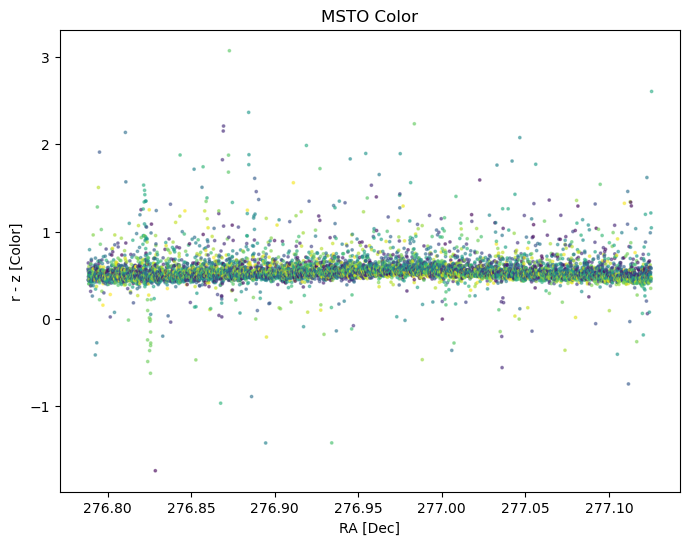

In [30]:
msto = photometric_catalog[(photometric_catalog[:, mag_col_index] >= magnitude_rc + 3.5) & 
                    (photometric_catalog[:, mag_col_index] < magnitude_rc + 3.5 + 0.5)]

msto_color = msto[:, c1_col_index] - msto[:, c2_col_index]
med_msto_color = np.nanmedian(msto_color)

# Plot main sequence turn off color as function of RA, color code by Dec
plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(msto[:, ra_col_index], msto_color, c = msto[:, dec_col_index], s = 3, alpha = 0.5)

plt.xlabel('RA [Dec]')
plt.ylabel(f"{color_band_1} - {color_band_2} [Color]")
plt.title('MSTO Color')

plt.show()

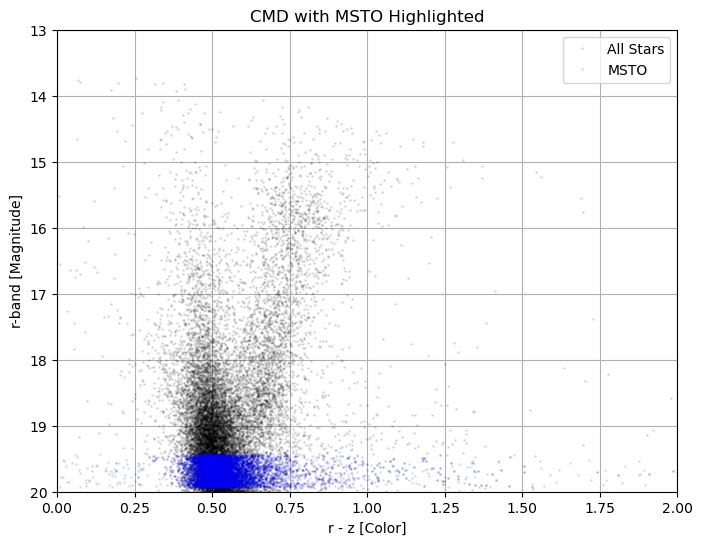

In [31]:
# Plot color-magnitude diagram with the MSTO highlighted
msto_magnitude = msto[:,mag_col_index]

plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.plot(color_index, magnitude_values, 'ko', ms = 1, alpha = 0.1, rasterized = True, 
        label = 'All Stars')
plt.plot(msto_color, msto_magnitude, 'bo', ms = 1, alpha = 0.1, rasterized = True, 
        label = 'MSTO')

plt.xlim([0,2])
plt.ylim([20,13])

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")
plt.title('CMD with MSTO Highlighted')

plt.grid(True)
plt.legend(loc = 'best')
plt.show()

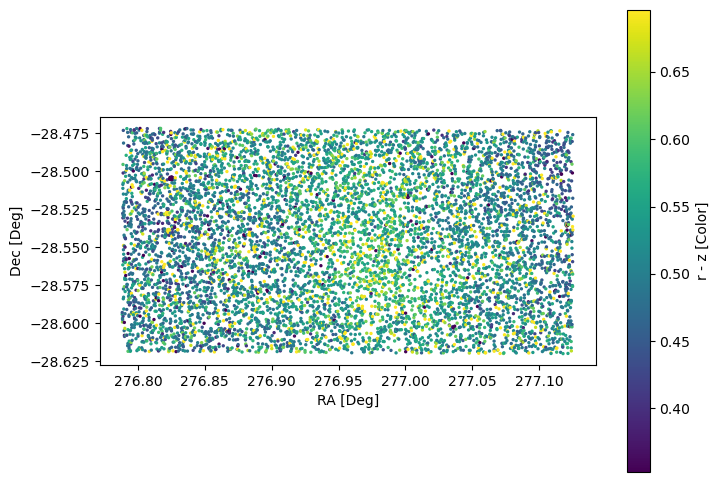

In [32]:
# Plots the color of the msto across the chip in RA and Dec. 
# Color coded by the median color +/- the standard deviation of the color
std_msto_color = np.nanstd(msto_color)

plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(msto[:, ra_col_index], msto[:, dec_col_index], c = msto_color, s = 2, vmin = med_msto_color - std_msto_color, vmax = med_msto_color + std_msto_color, rasterized = True)
color_bar = plt.colorbar()

plt.gca().set_aspect(1.0/np.cos(dec * np.pi/180.0))

color_bar.set_label(f"{color_band_1} - {color_band_2} [Color]")
plt.xlabel('RA [Deg]')
plt.ylabel('Dec [Deg]')

plt.show()

In [33]:
print("RA (Min, Median, Max):", ra_min, ra, ra_max)
print("Dec (Min, Med, Max):", dec_min, dec, dec_max)
print("Colorcut, Magcut:", default_color_cut, magnitude_cut)

RA (Min, Median, Max): 276.785594 276.9567274442114 277.126662
Dec (Min, Med, Max): -28.6213069 -28.545947733802898 -28.4704838
Colorcut, Magcut: 0.46 17.3


In [34]:
# Compute the color dispersion of MS and use it to quantify an error in reddening due to differential reddening
# across the field --> fit again as a function of ra and dec